# Notebook 02a — Depth Estimator: Classical Multi-Cue (ml-depth-pro Alternative from Scratch)

**Purpose:** Replace Apple's ml-depth-pro with a classical multi-cue monocular depth estimator.
No neural network. No GPU. Runs entirely on NumPy + OpenCV — and measure how far that gets us on FoodSeg103.

The neural baseline (ml-depth-pro) and the side-by-side comparison are in **02b_depth_estimator_depthpro.ipynb**.
Run this notebook first.

---

## 2. The Ill-Posedness Problem

Given a single image, infinitely many 3D scenes could produce the same 2D projection.
Neural networks resolve this by learning **scene priors** — the statistical regularities of how depth is distributed in the real world.

Without a network, we must rely on **domain-specific priors** — assumptions that hold for our specific scenario:
> *A smartphone photographing a food dish from ~50 cm above, on a table, with natural lighting.*

This is the key principle: **constrain the domain → reduce the ambiguity**.

## 3. The Five Classical Depth Cues

We fuse 5 monocular cues, each exploiting a known physical relationship:

| Cue | Physical Principle | Formula |
|---|---|---|
| **Defocus Blur** | Objects outside the focal plane are blurred | `sharpness = Var[∇²I]` in local patch |
| **Vertical Position** | On a flat table, higher-in-image = farther away | Linear gradient: bottom=near, top=far |
| **Local Contrast** | In-focus objects have higher local std deviation | `std = sqrt(E[I²] - E[I]²)` |
| **Dark Channel** | Haze (which increases with distance) raises the dark channel | `dark = min_channel(min_patch(I))` |
| **Colour Saturation** | Food is more saturated than the plate | HSV S-channel |

Fusion: `nearness = w₁·blur + w₂·position + w₃·contrast + w₄·(1-dark) + w₅·sat`

Then: `depth = scale × (1 - nearness)` — inverted so near=small depth, far=large depth.

## Evaluation protocol (shared by notebooks 02a and 02b)

FoodSeg103 has **no depth ground truth**, so depth maps are scored against what the dataset does have
(`foodseg_depth.py`; every map is compared at 384 px on its longest side):

| Metric | What it checks | Good value |
|---|---|---|
| `food_auroc` | Does nearness (−depth) separate food pixels from non-food pixels? Food sits on a plate, so it should be nearer the camera. | 1.0 (0.5 = chance) |
| `ring_order` | Fraction of food regions nearer than the ring of surface just around them (9 px band) | 1.0 |
| `height_mm` / `height_ok` | Median height of food above that surrounding surface; fraction of regions with 0 < h ≤ 100 mm. Only meaningful for **metric** depth. | 10–60 mm / 1.0 |
| `boundary_ratio` | Mean ‖∇ log depth‖ on GT region boundaries ÷ elsewhere – do depth edges follow object edges? | > 1 |
| `focal_rel_err` | Estimated focal length vs EXIF `FocalLengthIn35mmFilm` (only the ~3 % of images that still carry it) | 0 |
| `ref_*` | Agreement with **ml-depth-pro** as a pseudo reference, after median scaling: AbsRel, δ<1.25, SI-log, Spearman (all pixels and `ref_food_*` food pixels only) | AbsRel 0, δ1 1, Spearman 1 |
| `sec` | Median runtime per image | – |

Caveats:
- The mask metrics assume food sits *above* the surface around it. That fails for bowls and deep plates (the rim is
  nearer than the food) and for oblique shots, so even a perfect depth map does not reach 1.0.
- They are **necessary, not sufficient**: a map that simply highlights colourful, textured pixels scores well on
  `food_auroc` without encoding any geometry. Read them together with the `ref_*` agreement and the visualisations.
- ml-depth-pro is a strong model but not ground truth; only ~1.5 % of test images carry an EXIF focal length, and it
  assumes the image was resized, not cropped, from the camera original.
Results go to `outputs/depth/<estimator>_test.json`; notebook 02b puts them in one table.

## 4. Implementation

In [1]:
import math
import time
from dataclasses import dataclass
from typing import Optional

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

import foodseg_common as fc
import foodseg_depth as fd

SPLIT      = 'test'
TEST_LIMIT = None    # e.g. 100 for a quick run; None = whole test split (1069 images, CPU only, a few minutes)
VAL_LIMIT  = 200     # val images used for the cue ablation
NAME       = 'classical'

print('OpenCV:', cv2.__version__)

OpenCV: 4.13.0


In [2]:
@dataclass
class CameraIntrinsics:
    """
    Pinhole camera model parameters.
    
    fx, fy : focal lengths in pixels
      A point at real-world position (X, Y, Z) projects to pixel (u, v):
        u = fx * X/Z + cx
        v = fy * Y/Z + cy
    cx, cy : principal point (optical centre), usually ≈ (W/2, H/2)
    """
    fx: float
    fy: float
    cx: float
    cy: float
    width: int
    height: int
    source: str = "unknown"

    def as_matrix(self):
        """Return the 3×3 camera matrix K."""
        return np.array([
            [self.fx,  0,      self.cx],
            [0,        self.fy, self.cy],
            [0,        0,       1     ],
        ], dtype=np.float64)

print("CameraIntrinsics dataclass defined.")

CameraIntrinsics dataclass defined.


In [3]:
class ClassicalDepthEstimator:
    """
    Multi-cue monocular depth estimator.
    Drop-in replacement for utils/depth_estimator.py DepthEstimator.
    
    Parameters
    ----------
    fov_deg : float
        Assumed horizontal field of view (degrees). 70° = typical smartphone.
    assumed_plate_distance_m : float
        Scale anchor: assumed distance from camera to plate centre (metres).
    blur/position/contrast/dark/saturation _weight : float
        Relative contribution of each cue (auto-normalised to sum=1).
    """

    def __init__(self,
                 fov_deg=70.0,
                 assumed_plate_distance_m=0.5,
                 blur_weight=0.30,
                 position_weight=0.25,
                 contrast_weight=0.15,
                 dark_weight=0.15,
                 saturation_weight=0.15,
                 verbose=True):

        self.fov_deg = fov_deg
        self.assumed_plate_distance_m = assumed_plate_distance_m
        self.verbose = verbose

        total = blur_weight + position_weight + contrast_weight + dark_weight + saturation_weight
        self.w = {
            'blur': blur_weight      / total,
            'pos' : position_weight  / total,
            'con' : contrast_weight  / total,
            'dark': dark_weight      / total,
            'sat' : saturation_weight/ total,
        }
        if verbose:
            print("[ClassicalDepth] Cue weights:", {k: f"{v:.2f}" for k,v in self.w.items()})

    # ── Public API ────────────────────────────────────────────────────

    def estimate(self, bgr_image, image_path=None):
        """
        Produce a metric depth map and camera intrinsics.
        Same interface as DepthEstimator.estimate() in utils/depth_estimator.py.
        """
        H, W = bgr_image.shape[:2]
        intrinsics = self._intrinsics_from_fov(W, H)

        # Compute each cue
        blur = self._cue_defocus_blur(bgr_image)
        pos  = self._cue_vertical_position(H, W)
        con  = self._cue_local_contrast(bgr_image)
        dark = self._cue_dark_channel(bgr_image)
        sat  = self._cue_saturation(bgr_image)

        # Fuse → nearness map [0=far, 1=near]
        nearness = (
            self.w['blur'] * blur +
            self.w['pos']  * pos  +
            self.w['con']  * con  +
            self.w['dark'] * (1.0 - dark) +  # dark channel: high=far → invert
            self.w['sat']  * sat
        )

        # Convert relative nearness → metric depth
        depth_rel = np.clip(1.0 - nearness, 1e-3, 1.0)
        scale = self.assumed_plate_distance_m / max(float(np.median(depth_rel)), 1e-3)
        depth_metric = (depth_rel * scale).astype(np.float32)

        if self.verbose:
            print(f"[ClassicalDepth] Depth range: {depth_metric.min():.3f} – {depth_metric.max():.3f} m")
        return depth_metric, intrinsics, {'blur':blur, 'pos':pos, 'con':con, 'dark':dark, 'sat':sat}

    # ── Cue 1: Defocus Blur ───────────────────────────────────────────

    def _cue_defocus_blur(self, bgr, window=15):
        """
        Local variance of the Laplacian — measures sharpness.
        
        Laplacian: L = ∂²I/∂x² + ∂²I/∂y² (second derivative in x and y)
        In discrete form: L(x,y) = I(x-1,y)+I(x+1,y)+I(x,y-1)+I(x,y+1) - 4·I(x,y)
        
        Sharpness = Var[L] in a local window.
        High variance = sharp = near camera.
        """
        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).astype(np.float32)
        lap  = cv2.Laplacian(gray, cv2.CV_32F, ksize=3)
        k    = (window, window)
        # Var[X] = E[X²] - E[X]²
        m1   = cv2.boxFilter(lap,    cv2.CV_32F, k)
        m2   = cv2.boxFilter(lap**2, cv2.CV_32F, k)
        var  = np.clip(m2 - m1**2, 0, None)
        return self._norm(var)

    # ── Cue 2: Vertical Position ──────────────────────────────────────

    def _cue_vertical_position(self, H, W):
        """
        Perspective prior: lower in image = nearer (for scenes on a flat table).
        Linear gradient from 0 (top=far) to 1 (bottom=near).
        """
        return np.tile(np.linspace(0, 1, H, dtype=np.float32)[:, None], (1, W))

    # ── Cue 3: Local Contrast ─────────────────────────────────────────

    def _cue_local_contrast(self, bgr, window=21):
        """
        Local standard deviation of pixel intensities.
        High std = rich visual detail = likely in-focus foreground = near.
        """
        gray  = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).astype(np.float32)
        k     = (window, window)
        mean  = cv2.boxFilter(gray,    cv2.CV_32F, k)
        mean2 = cv2.boxFilter(gray**2, cv2.CV_32F, k)
        var   = np.clip(mean2 - mean**2, 0, None)
        return self._norm(np.sqrt(var))

    # ── Cue 4: Dark Channel Prior ─────────────────────────────────────

    def _cue_dark_channel(self, bgr, patch_size=15):
        """
        He et al. (CVPR 2009): dark_channel = min over colour channels and patch.
        
        In haze-free regions: dark channel ≈ 0.
        Hazy (distant) regions: dark channel > 0.
        So dark channel ≈ proxy for DISTANCE (high = far).
        
        Returns the dark channel map. Caller inverts it to get nearness.
        """
        min_ch = bgr.min(axis=2).astype(np.float32) / 255.0
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (patch_size, patch_size))
        dark   = cv2.erode(min_ch, kernel)   # min over patch = morphological erosion
        return dark  # [0,1], high = far

    # ── Cue 5: Saturation ─────────────────────────────────────────────

    def _cue_saturation(self, bgr):
        """
        HSV S-channel: food is colourful (saturated), plate is white/grey.
        High saturation → food → nearer to camera.
        """
        hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV).astype(np.float32)
        sat = hsv[:,:,1] / 255.0
        return cv2.GaussianBlur(sat, (11,11), 0)

    # ── Camera intrinsics ─────────────────────────────────────────────

    def _intrinsics_from_fov(self, W, H):
        """
        Compute focal length (in pixels) from FOV angle.
        
        Derivation: at the image edge, the angle from optical axis = FOV/2.
        The edge pixel is at distance W/2 from the optical centre.
        From the pinhole model: (W/2) = fx * tan(FOV/2)
        → fx = (W/2) / tan(FOV/2)
        """
        fov_rad = math.radians(self.fov_deg)
        fx = (W / 2.0) / math.tan(fov_rad / 2.0)
        fy = fx * (H / W)
        return CameraIntrinsics(fx=fx, fy=fy, cx=W/2, cy=H/2, width=W, height=H, source="fov_prior")

    # ── Utility ───────────────────────────────────────────────────────

    @staticmethod
    def _norm(arr):
        lo, hi = arr.min(), arr.max()
        if hi - lo < 1e-8: return np.zeros_like(arr, dtype=np.float32)
        return ((arr - lo) / (hi - lo)).astype(np.float32)

    @staticmethod
    def visualise(depth_map):
        """Convert float depth map to BGR image (INFERNO colourmap: dark=far, yellow=near)."""
        lo, hi = depth_map.min(), depth_map.max()
        norm = ((depth_map - lo) / (hi - lo + 1e-8) * 255).astype(np.uint8)
        return cv2.applyColorMap(255 - norm, cv2.COLORMAP_INFERNO)

print("ClassicalDepthEstimator defined.")

ClassicalDepthEstimator defined.


## 5. Demo — Visualise Each Cue

In [4]:
# ── Use a real FoodSeg103 test image ───────────────────────────────────────
DEMO_ID       = fc.read_split_ids(SPLIT)[0]
img           = cv2.cvtColor(fc.load_rgb(fc.image_path(SPLIT, DEMO_ID)), cv2.COLOR_RGB2BGR)
DEMO_ANN_MASK = fc.load_label_mask(fc.mask_path(SPLIT, DEMO_ID))
H, W = img.shape[:2]
print(f"Loaded: {DEMO_ID}  ({W}x{H}), {len(np.unique(DEMO_ANN_MASK)) - 1} food classes in the mask")

est = ClassicalDepthEstimator()
depth_map, intrinsics, cues = est.estimate(img)

print(f"Depth range: {depth_map.min():.3f} m — {depth_map.max():.3f} m")

Loaded: 00005942  (512x384), 5 food classes in the mask
[ClassicalDepth] Cue weights: {'blur': '0.30', 'pos': '0.25', 'con': '0.15', 'dark': '0.15', 'sat': '0.15'}
[ClassicalDepth] Depth range: 0.166 – 0.724 m
Depth range: 0.166 m — 0.724 m


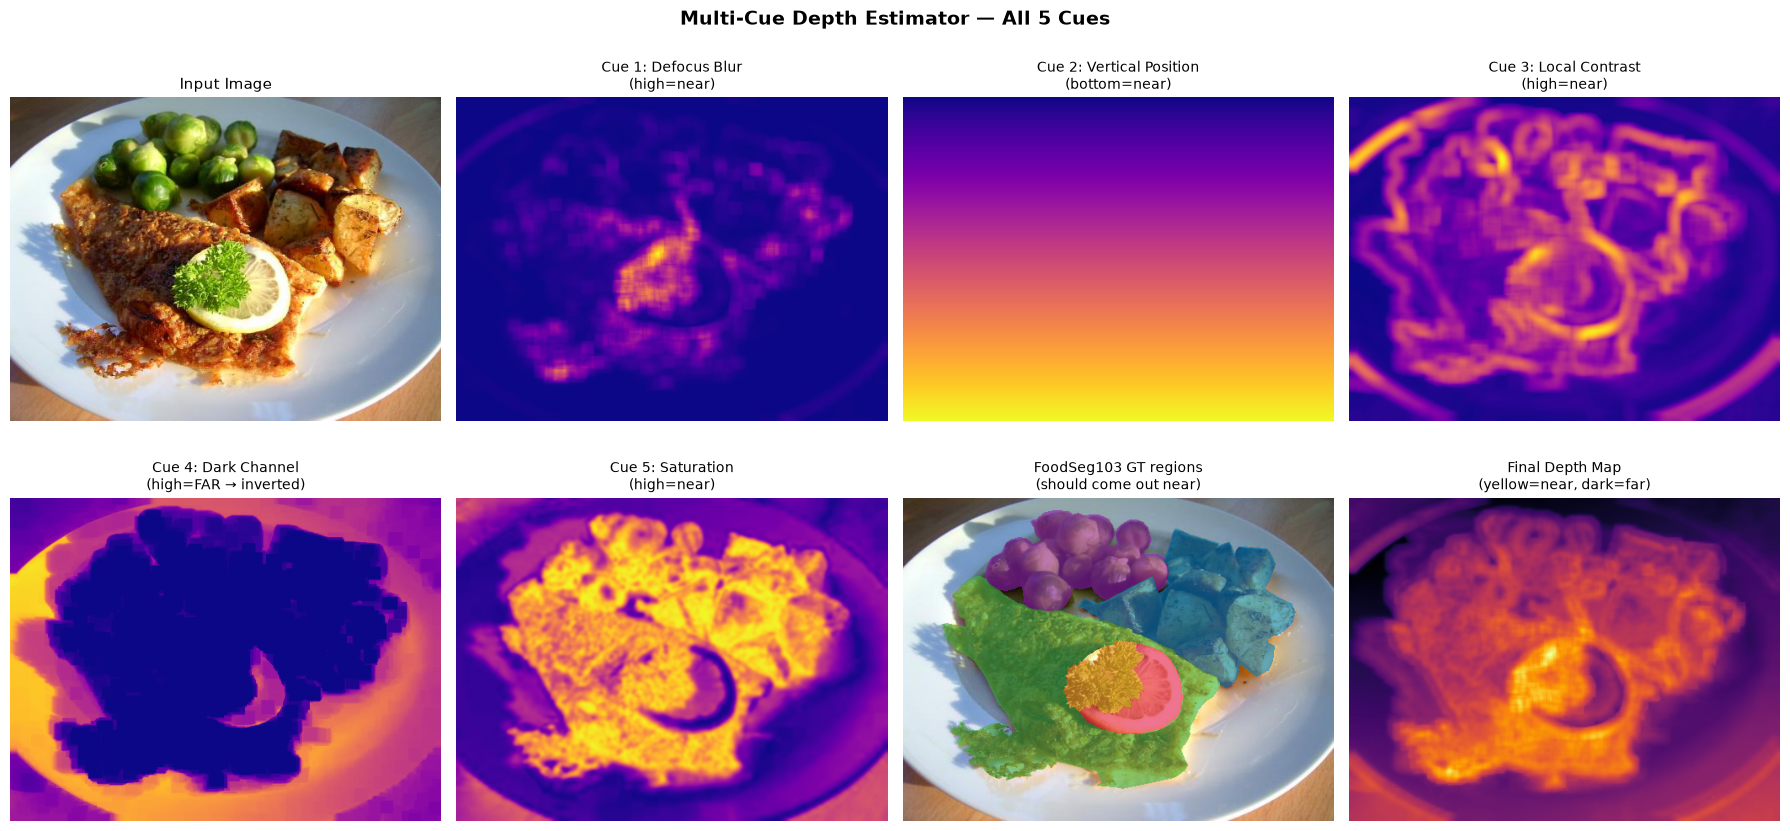

Mask metrics for this image: {'food_auroc': 0.918, 'ring_order': 0.75, 'height_mm': 107.887, 'height_ok': 0.0, 'n_regions': 4, 'boundary_ratio': 2.298, 'median_depth_m': 0.5}


In [5]:
# Visualise all 5 cues + GT mask + final depth map
fig, axes = plt.subplots(2, 4, figsize=(18, 9))

axes[0,0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0,0].set_title("Input Image", fontsize=11); axes[0,0].axis("off")

for ax, (name, label) in zip(axes.flat[1:], [
    ('blur', 'Cue 1: Defocus Blur\n(high=near)'),
    ('pos',  'Cue 2: Vertical Position\n(bottom=near)'),
    ('con',  'Cue 3: Local Contrast\n(high=near)'),
    ('dark', 'Cue 4: Dark Channel\n(high=FAR → inverted)'),
    ('sat',  'Cue 5: Saturation\n(high=near)'),
]):
    ax.imshow(cues[name], cmap='plasma', vmin=0, vmax=1)
    ax.set_title(label, fontsize=10); ax.axis("off")

axes[1,2].imshow(fc.overlay(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), fc.gt_instances(DEMO_ANN_MASK)))
axes[1,2].set_title("FoodSeg103 GT regions\n(should come out near)", fontsize=10); axes[1,2].axis("off")

vis = ClassicalDepthEstimator.visualise(depth_map)
axes[1,3].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
axes[1,3].set_title("Final Depth Map\n(yellow=near, dark=far)", fontsize=10); axes[1,3].axis("off")

plt.suptitle("Multi-Cue Depth Estimator — All 5 Cues", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

print('Mask metrics for this image:', {k: round(v, 3) for k, v in
      fd.mask_metrics(fd.to_eval(depth_map), fd.eval_label_mask(SPLIT, DEMO_ID)).items()})

## 6. From Depth Map to 3D Points (Backprojection)

The depth map is useful, but volume estimation needs 3D coordinates.
We use the **pinhole camera model** to 'unproject' each pixel into 3D space:

```
For pixel (u, v) with depth Z:
  X = (u - cx) × Z / fx
  Y = (v - cy) × Z / fy  
  Z = Z
```

This is the inverse of the projection equation. Let's visualise the resulting point cloud.

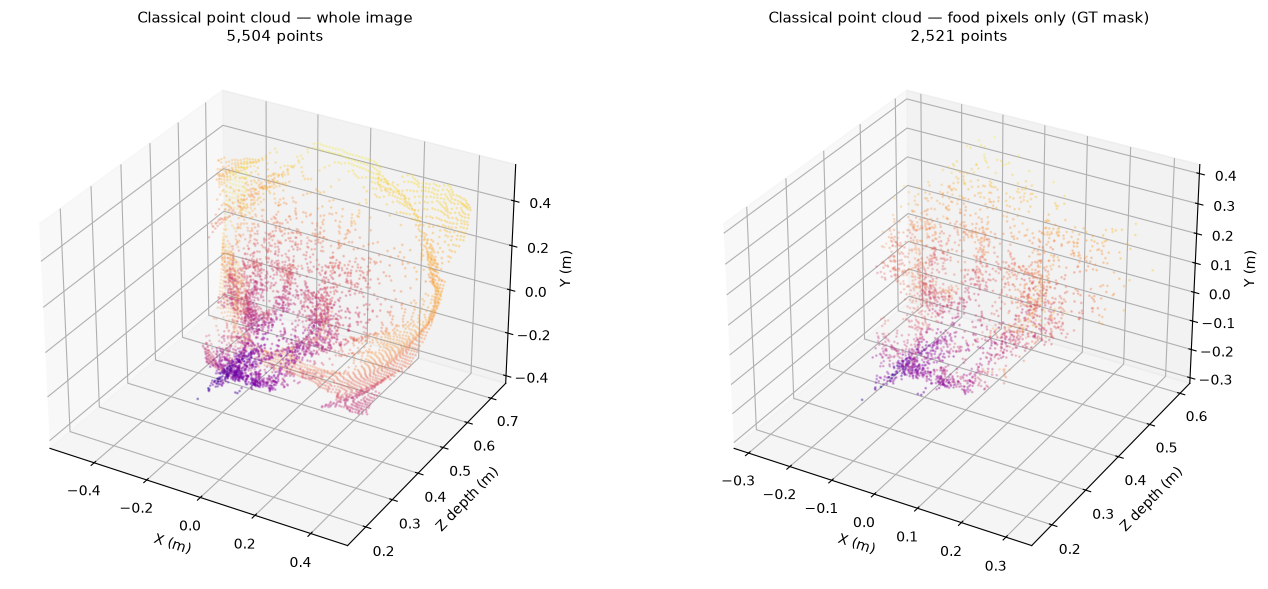

In [6]:
from mpl_toolkits.mplot3d import Axes3D

def backproject(depth_map, intrinsics, mask=None, stride=4):
    """
    Convert (selected) depth pixels to 3D points.
    stride: subsample every `stride` pixels for speed.
    """
    H, W = depth_map.shape
    vs, us = np.mgrid[0:H:stride, 0:W:stride]
    zs = depth_map[vs, us]

    if mask is not None:
        valid = (zs > 0) & (mask[vs, us] > 127)
    else:
        valid = zs > 0

    u, v, z = us[valid].ravel(), vs[valid].ravel(), zs[valid].ravel()
    X = (u - intrinsics.cx) * z / intrinsics.fx
    Y = (v - intrinsics.cy) * z / intrinsics.fy
    return np.stack([X, Y, z], axis=1)

food_mask = (DEMO_ANN_MASK > 0).astype(np.uint8) * 255
fig = plt.figure(figsize=(14, 6))
for k, (mask, title) in enumerate([(None, 'whole image'), (food_mask, 'food pixels only (GT mask)')]):
    pts = backproject(depth_map, intrinsics, mask=mask, stride=6)
    ax  = fig.add_subplot(1, 2, k + 1, projection='3d')
    colours = plt.cm.plasma((pts[:,2] - pts[:,2].min()) / (pts[:,2].max() - pts[:,2].min() + 1e-8))
    ax.scatter(pts[:,0], pts[:,2], -pts[:,1], c=colours, s=1, alpha=0.6)
    ax.set_xlabel("X (m)"); ax.set_ylabel("Z depth (m)"); ax.set_zlabel("Y (m)")
    ax.set_title(f"Classical point cloud — {title}\n{pts.shape[0]:,} points", fontsize=11)
plt.tight_layout(); plt.show()

## 7. Evaluation on the FoodSeg103 test split

Run the estimator on every test image, cache the depth maps (`outputs/depth/classical_test.pkl`, reused by 02b for
the agreement with ml-depth-pro) and score them with the protocol above. The camera focal length is the FOV prior
(70°), which is what `focal_rel_err` measures on the EXIF subset.

In [7]:
est = ClassicalDepthEstimator(verbose=False)

def classical_estimate(rgb, sid):
    depth, K, _ = est.estimate(cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))
    return depth, K.fx

test_ids = fc.read_split_ids(SPLIT)[:TEST_LIMIT]
cache = fd.run_depth(classical_estimate, SPLIT, test_ids, name=NAME, progress=tqdm)

exif = fd.exif_focals(SPLIT, test_ids)
ref  = fd.load_depth_cache('depth_pro', SPLIT) or None    # present once 02b has run
summary, rows = fd.evaluate(cache, SPLIT, ref_cache=ref, exif=exif)
fd.save_result(NAME, SPLIT, summary, extra=dict(weights=est.w, fov_deg=est.fov_deg,
                                                plate_distance_m=est.assumed_plate_distance_m))
per_image = pd.DataFrame(rows).set_index('id')
print(f'{len(cache)} images, {len(exif)} with EXIF focal length'
      + ('' if ref else ' — no ml-depth-pro cache yet, run 02b for the ref_* metrics'))
pd.Series(summary).round(4).to_frame(NAME)

  0%|          | 0/1069 [00:00<?, ?it/s]

1069 images, 16 with EXIF focal length — no ml-depth-pro cache yet, run 02b for the ref_* metrics


,classical
sec,0.0206
f_px,527.7307
hfov_deg,70.0000
food_auroc,0.7119
ring_order,0.7395
height_mm,41.0156
height_ok,0.5913
n_regions,3.5248
boundary_ratio,1.7627
median_depth_m,0.5000


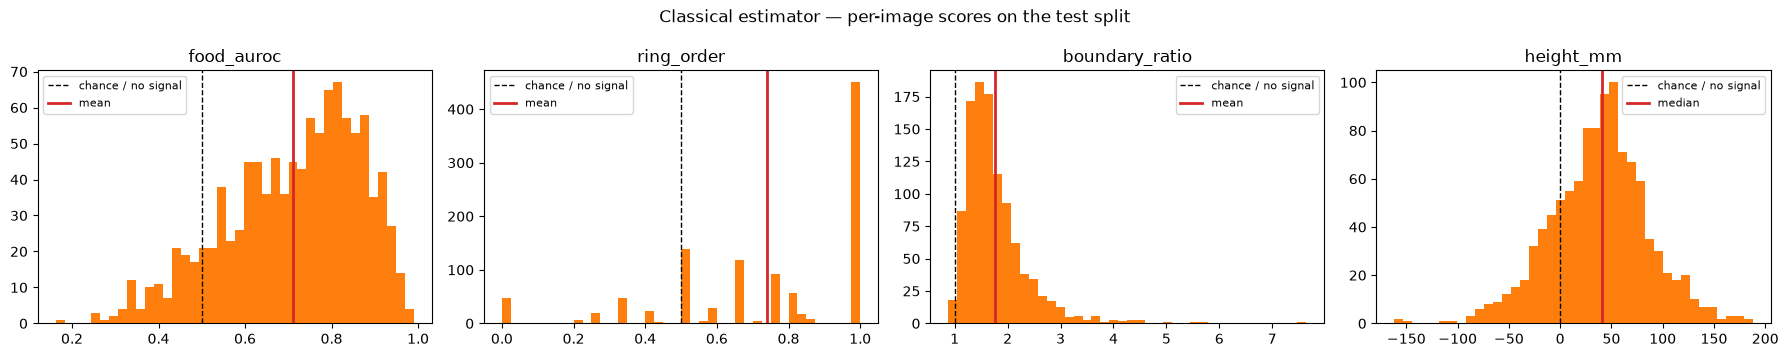

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, col, ref_line in zip(axes, ['food_auroc', 'ring_order', 'boundary_ratio', 'height_mm'], [0.5, 0.5, 1.0, 0.0]):
    v = per_image[col].dropna()
    ax.hist(v, bins=40, color='tab:orange')
    ax.axvline(ref_line, color='k', ls='--', lw=1, label='chance / no signal')
    ax.axvline(v.mean() if col != 'height_mm' else v.median(), color='tab:red', lw=2, label='mean' if col != 'height_mm' else 'median')
    ax.set_title(col); ax.legend(fontsize=8)
plt.suptitle('Classical estimator — per-image scores on the test split'); plt.tight_layout(); plt.show()

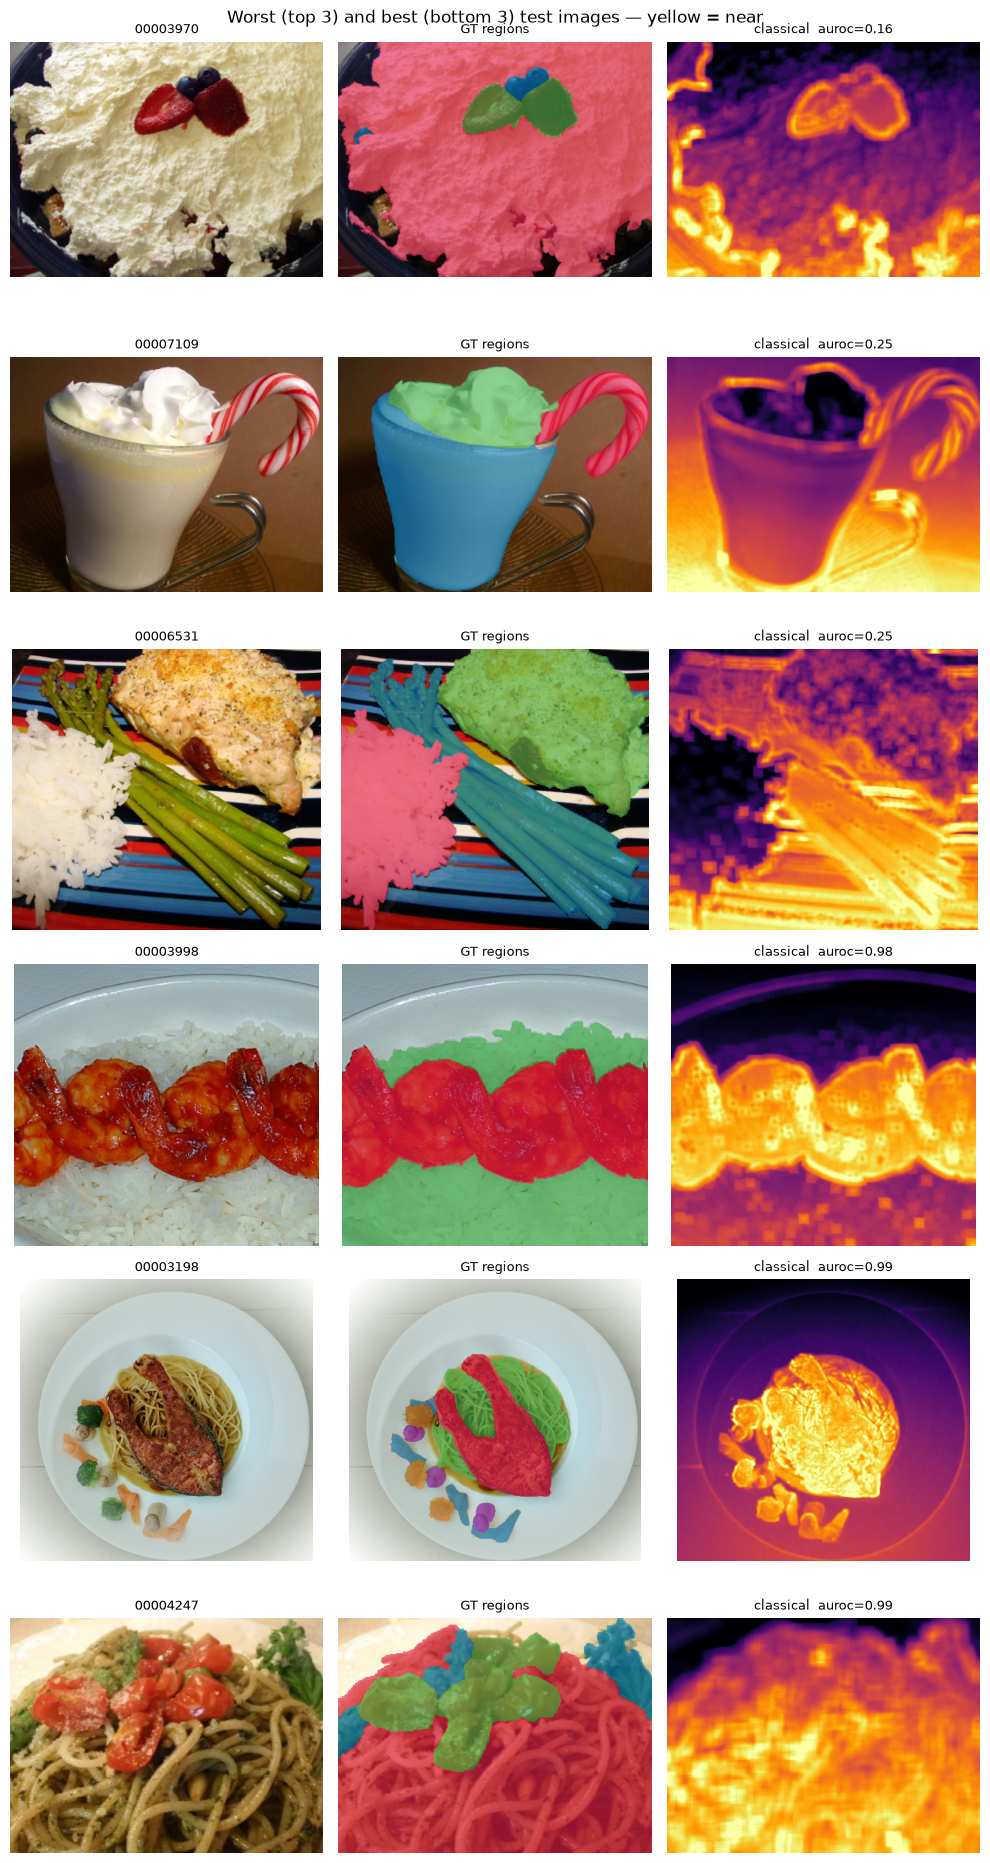

In [9]:
# Best and worst images by food_auroc
order = per_image['food_auroc'].dropna().sort_values()
pick = list(order.index[:3]) + list(order.index[-3:])
fig, axes = plt.subplots(len(pick), 3, figsize=(10, 3.2 * len(pick)))
for row, sid in zip(axes, pick):
    rgb = fc.load_rgb(fc.image_path(SPLIT, sid))
    lm = fd.eval_label_mask(SPLIT, sid)
    rgb = cv2.resize(rgb, lm.shape[::-1], interpolation=cv2.INTER_AREA)
    row[0].imshow(rgb); row[0].set_title(sid, fontsize=9)
    row[1].imshow(fc.overlay(rgb, fc.gt_instances(lm, min_area=1))); row[1].set_title('GT regions', fontsize=9)
    row[2].imshow(fd.colourise(cache[sid]['depth'].astype(np.float32)))
    row[2].set_title(f"classical  auroc={per_image.loc[sid, 'food_auroc']:.2f}", fontsize=9)
    for ax in row: ax.axis('off')
plt.suptitle('Worst (top 3) and best (bottom 3) test images — yellow = near'); plt.tight_layout(); plt.show()

## 8. Cue ablation (val split)

Which cues actually carry depth information for food photos? The cues are computed once per val image and fused
with different weights: all five (default weights), each cue on its own, and each cue left out.
This answers exercise 1 of the original notebook quantitatively. Tuning is done on **val**, never on test.

In [10]:
CUES = ['blur', 'pos', 'con', 'dark', 'sat']

def fuse(cue_maps, weights, plate_m=est.assumed_plate_distance_m):
    """Same fusion as ClassicalDepthEstimator.estimate, for arbitrary weights."""
    w = np.array([weights.get(k, 0.0) for k in CUES], dtype=np.float64)
    w /= w.sum()
    near = sum(wi * (1.0 - cue_maps[k] if k == 'dark' else cue_maps[k]) for wi, k in zip(w, CUES))
    rel = np.clip(1.0 - near, 1e-3, 1.0)
    return rel * plate_m / max(float(np.median(rel)), 1e-3)

configs = {'all (default)': dict(est.w)}
configs.update({f'only {k}': {k: 1.0} for k in CUES})
configs.update({f'without {k}': {c: v for c, v in est.w.items() if c != k} for k in CUES})

val_ids = fc.read_split_ids('val')[:VAL_LIMIT]
abl = {name: [] for name in configs}
for sid in tqdm(val_ids):
    bgr = cv2.cvtColor(fc.load_rgb(fc.image_path('val', sid)), cv2.COLOR_RGB2BGR)
    _, _, cue_maps = est.estimate(bgr)
    lm = fd.eval_label_mask('val', sid)
    cue_maps = {k: cv2.resize(v, lm.shape[::-1], interpolation=cv2.INTER_AREA) for k, v in cue_maps.items()}
    for name, w in configs.items():
        abl[name].append(fd.mask_metrics(fuse(cue_maps, w), lm))

cols = ['food_auroc', 'ring_order', 'boundary_ratio']
ablation = pd.DataFrame({name: pd.DataFrame(r)[cols].mean() for name, r in abl.items()}).T
ablation.to_csv(fd.DEPTH_ROOT / 'classical_cue_ablation_val.csv')
ablation.round(3)

  0%|          | 0/200 [00:00<?, ?it/s]

,food_auroc,ring_order,boundary_ratio
all (default),0.713,0.739,1.789
only blur,0.701,0.594,1.663
only pos,0.491,0.499,0.576
only con,0.644,0.325,1.815
only dark,0.725,0.674,1.515
only sat,0.800,0.850,2.366
without blur,0.704,0.739,1.964
without pos,0.766,0.754,1.865
without con,0.713,0.781,1.983
without dark,0.669,0.731,1.942


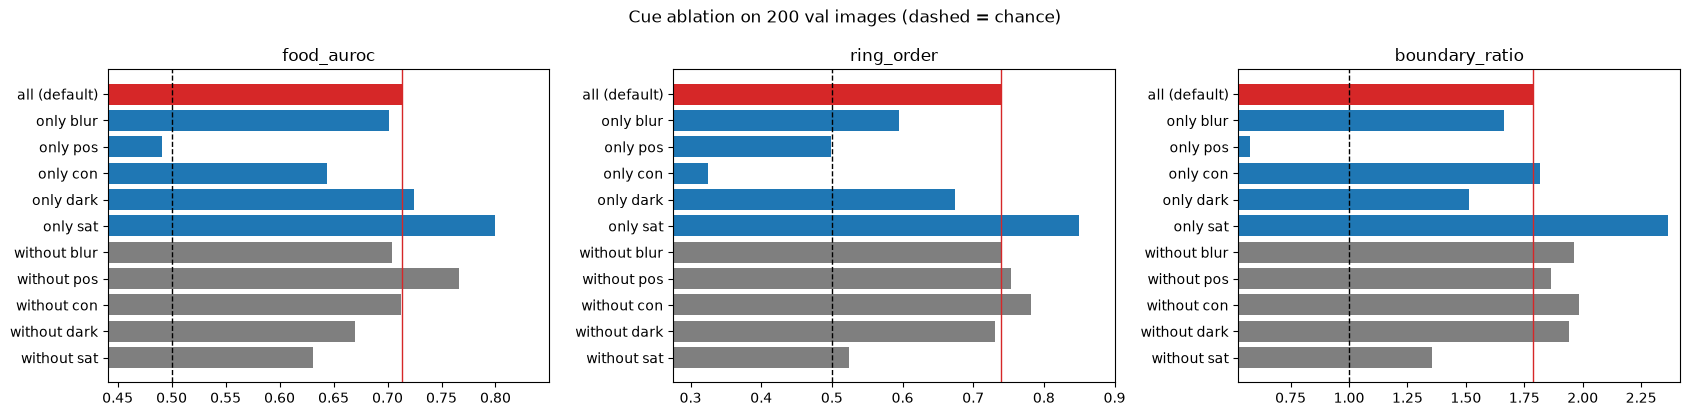

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, col, chance in zip(axes, cols, [0.5, 0.5, 1.0]):
    s = ablation[col]
    ax.barh(s.index[::-1], s.values[::-1],
            color=['tab:red' if n.startswith('all') else 'tab:blue' if n.startswith('only') else 'tab:gray'
                   for n in s.index[::-1]])
    ax.axvline(chance, color='k', ls='--', lw=1)
    ax.axvline(s['all (default)'], color='tab:red', lw=1)
    ax.set_title(col); ax.set_xlim(min(s.min(), chance) - 0.05, max(s.max(), chance) + 0.05)
plt.suptitle(f'Cue ablation on {len(val_ids)} val images (dashed = chance)'); plt.tight_layout(); plt.show()